# Research question
Can features extracted from labeled emails predict whether an unseen email is spam or ham? Each row represents one email, its 57 numeric predictors describe its contents and its known label is the outcome 1/0.

In [ ]:
import sys
from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

SEED = 42
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False})
print('Python:', sys.version.split()[0])
print('scikit-learn:', sklearn.__version__)

Python: 3.12.14
scikit-learn: 1.8.0


# Load data
The original UCI dataset has 4,601 emails and 57 predictors: 48 word frequency percentages, 6 character frequency percentages, and 3 capital letter run summaries.

In [ ]:
data_dir = Path('data')
required = ['spambase.data', 'spambase.names']
if not all((data_dir / name).exists() for name in required):
    url = 'https://archive.ics.uci.edu/static/public/94/spambase.zip'
    try:
        with urlopen(url, timeout=60) as response:
            archive = ZipFile(BytesIO(response.read()))
        data_dir.mkdir(exist_ok=True)
        for name in required + ['spambase.DOCUMENTATION']:
            (data_dir / name).write_bytes(archive.read(name))
    except Exception as exc:
        raise RuntimeError('Download failed. Extract the provided ZIP and keep its data '
                           'folder next to this notebook, then rerun.') from exc

names_text = (data_dir / 'spambase.names').read_text()
feature_names = [line.split(':', 1)[0].strip()
                 for line in names_text.splitlines()
                 if ':' in line and line.split(':', 1)[1].strip() == 'continuous.']
assert len(feature_names) == 57
df = pd.read_csv(data_dir / 'spambase.data', header=None,
                 names=feature_names + ['spam'])
assert df.shape == (4601, 58)
assert set(df['spam'].unique()) == {0, 1}
assert (df[feature_names].dropna() >= 0).all().all()
print('Emails:', len(df), '| Predictors:', len(feature_names))
print('Missing values:', df.isna().sum().sum())
print('Repeated complete rows:', df.duplicated().sum())
display(df.head())
display(df['spam'].value_counts().sort_index().rename(index={0:'Ham', 1:'Spam'})
        .to_frame('Emails').assign(Percent=lambda x: 100*x['Emails']/len(df)))

Emails: 4601 | Predictors: 57
Missing values: 0
Repeated complete rows: 391


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,word_freq_receive,word_freq_will,word_freq_people,word_freq_report,word_freq_addresses,word_freq_free,word_freq_business,word_freq_email,word_freq_you,word_freq_credit,word_freq_your,word_freq_font,word_freq_000,word_freq_money,word_freq_hp,word_freq_hpl,word_freq_george,word_freq_650,word_freq_lab,word_freq_labs,word_freq_telnet,word_freq_857,word_freq_data,word_freq_415,word_freq_85,word_freq_technology,word_freq_1999,word_freq_parts,word_freq_pm,word_freq_direct,word_freq_cs,word_freq_meeting,word_freq_original,word_freq_project,word_freq_re,word_freq_edu,word_freq_table,word_freq_conference,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,0.00,0.64,0.00,0.00,0.00,0.32,0.00,1.29,1.93,0.00,0.96,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,0.21,0.79,0.65,0.21,0.14,0.14,0.07,0.28,3.47,0.00,1.59,0.0,0.43,0.43,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.07,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,0.38,0.45,0.12,0.00,1.75,0.06,0.06,1.03,1.36,0.32,0.51,0.0,1.16,0.06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.06,0.0,0.0,0.12,0.0,0.06,0.06,0.0,0.0,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,0.31,0.31,0.31,0.00,0.00,0.31,0.00,0.00,3.18,0.00,0.31,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,0.31,0.31,0.31,0.00,0.00,0.31,0.00,0.00,3.18,0.00,0.31,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


,Emails,Percent
spam,,
Ham,2788,60.595523
Spam,1813,39.404477


# Avoid duplicate leakage
Some records have identical features, so randomly splitting rows can put an identical vector in training and testing and effecting our results. We retain all records but keep identical feature vectors in the same group no matter the label. This also handles the small number of vectors associated with conflicting labels. Split the data into approximately 80% training and 20% testing while keeping related observations in the same group and maintaining similar class proportions. The percentages may vary slightly due to these group constraints but I use five fold grouped cross validation on the training data to select the best classifier.

In [ ]:
X = df[feature_names].copy()
y = df['spam'].astype(int)
# A group is an exact tuple of the 57 recorded predictor values.
groups = pd.Series(pd.factorize(pd.MultiIndex.from_frame(X))[0], index=X.index)
outer_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer_split.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]
assert set(groups_train).isdisjoint(set(groups_test))
split_summary = pd.DataFrame({
    'Set': ['Training', 'Test'],
    'Emails': [len(y_train), len(y_test)],
    'Ham': [(y_train==0).sum(), (y_test==0).sum()],
    'Spam': [y_train.sum(), y_test.sum()],
    'Spam percent': [100*y_train.mean(), 100*y_test.mean()]})
display(split_summary.round(2))
print('Overlapping feature groups: 0')

Overlapping feature groups: 0


,Set,Emails,Ham,Spam,Spam percent
0,Training,3680,2230,1450,39.40
1,Test,921,558,363,39.41


# Frequencies

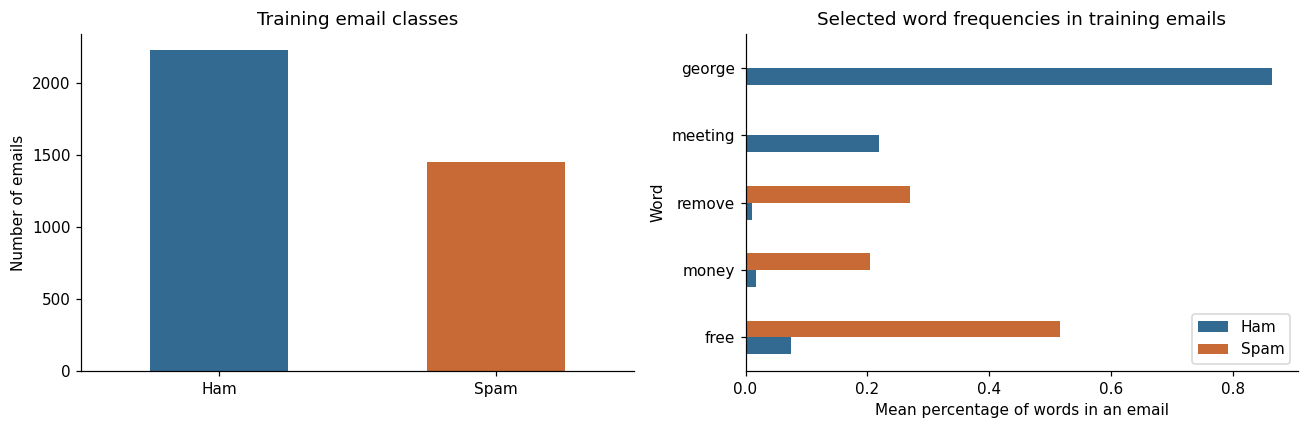

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
y_train.value_counts().sort_index().rename(index={0:'Ham', 1:'Spam'}).plot.bar(
    ax=axes[0], color=['#336A91', '#C76A35'], rot=0)
axes[0].set(title='Training email classes', ylabel='Number of emails', xlabel='')
selected_words = ['word_freq_free', 'word_freq_money', 'word_freq_remove',
                  'word_freq_meeting', 'word_freq_george']
means = X_train.assign(spam=y_train).groupby('spam')[selected_words].mean().T
means.columns = ['Ham', 'Spam']
means.index = means.index.str.replace('word_freq_', '', regex=False)
means.plot.barh(ax=axes[1], color=['#336A91', '#C76A35'])
axes[1].set(title='Selected word frequencies in training emails',
            xlabel='Mean percentage of words in an email', ylabel='Word')
plt.tight_layout()
plt.show()

# Compare Classifiers
For Naive Bayes and logistic regression, log1p is used to reduce skewness, while standardization puts the predictors on similar scales. Gaussian Naive Bayes is used because the predictors are continuous values rather than just raw word counts but its assumptions may not fully reflect the data. Random forest uses the original predictor scales. All preprocessing is performed within each training fold using pipelines to prevent data leakage.

Model settings are determined in advance because the goal is to compare different classifiers rather than optimize their parameters. The model with the highest average cross validation F1 score for spam is selected. F1 balances precision and recall but does not specifically account for the cost of incorrectly classifying legitimate emails as spam. Accuracy, precision, recall, and ROC AUC are also reported for evaluation of model performance.

The feature importance results show that the random forest relied on a combination of character frequencies and word frequencies to distinguish spam from legitimate email. The three most important predictors were the frequency of exclamation marks with the word “remove,” and dollar signs. Words like “hp,” “our,” “edu,” and “free” also had som eeffect to the model’s predictions. These findings suggest that both punctuation patterns and vocabulary helped the model identify differences between the two email classes but permutation importance measures how much a feature supports prediction.

In [ ]:
def transformed_pipeline(model):
    return make_pipeline(SimpleImputer(strategy='median'),
                         FunctionTransformer(np.log1p, feature_names_out='one-to-one'),
                         StandardScaler(), model)

models = {
    'Majority baseline': make_pipeline(SimpleImputer(strategy='median'),
                                      DummyClassifier(strategy='most_frequent')),
    'Gaussian Naive Bayes': transformed_pipeline(GaussianNB()),
    'Logistic regression': transformed_pipeline(
        LogisticRegression(max_iter=3000, random_state=SEED)),
    'Random forest': make_pipeline(SimpleImputer(strategy='median'),
        RandomForestClassifier(n_estimators=250, min_samples_leaf=2,
                               max_features='sqrt', random_state=SEED, n_jobs=1))
}
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED+1)
folds = list(cv.split(X_train, y_train, groups_train))
for a, b in folds:
    assert set(groups_train.iloc[a]).isdisjoint(set(groups_train.iloc[b]))
scoring = {'accuracy':'accuracy', 'precision':'precision', 'recall':'recall',
           'f1':'f1', 'roc_auc':'roc_auc'}

from sklearn.metrics import make_scorer
scoring['precision'] = make_scorer(precision_score, zero_division=0)
rows=[]
for name, pipeline in models.items():
    scores = cross_validate(pipeline, X_train, y_train, cv=folds,
                            scoring=scoring, n_jobs=1, error_score='raise')
    row={'Model':name}
    for metric in scoring:
        row[metric] = scores['test_'+metric].mean()
    row['f1_std'] = scores['test_f1'].std(ddof=1)
    rows.append(row)
cv_results = pd.DataFrame(rows).sort_values('f1', ascending=False).reset_index(drop=True)
display(cv_results.round(4))
best_name = cv_results.iloc[0]['Model']
best_model = models[best_name]
print('Selected using training CV:', best_name)

Selected using training CV: Random forest


,Model,accuracy,precision,recall,f1,roc_auc,f1_std
0,Random forest,0.9427,0.9478,0.9048,0.9255,0.9835,0.0117
1,Logistic regression,0.9378,0.9261,0.9159,0.9205,0.9789,0.0148
2,Gaussian Naive Bayes,0.8160,0.6960,0.9490,0.8028,0.9381,0.0152
3,Majority baseline,0.6060,0.0000,0.0000,0.0000,0.5000,0.0000


Out[6]: 
Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('randomforestclassifier',
                 RandomForestClassifier(min_samples_leaf=2, n_estimators=250,
                                        n_jobs=1, random_state=42))])


,Feature,Mean F1 decrease,SD
51,char_freq_!,0.0187,0.0071
6,word_freq_remove,0.0167,0.0043
52,char_freq_$,0.0153,0.0062
24,word_freq_hp,0.0090,0.0034
4,word_freq_our,0.0087,0.0026
45,word_freq_edu,0.0068,0.0020
15,word_freq_free,0.0066,0.0060
26,word_freq_george,0.0060,0.0034
22,word_freq_000,0.0054,0.0009
21,word_freq_font,0.0041,0.0006


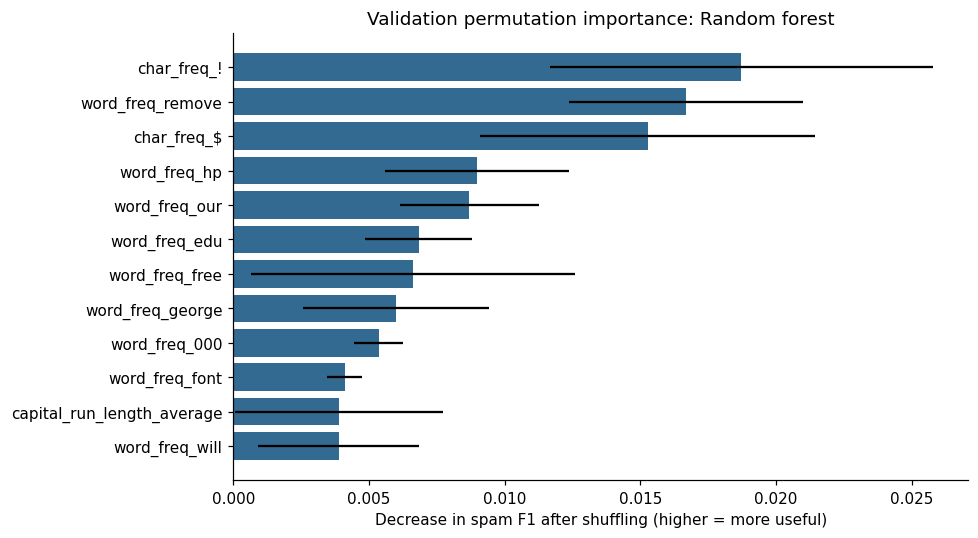

In [ ]:
from sklearn.base import clone
fit_idx, val_idx = folds[0]
interpretation_model = clone(best_model).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
importance = permutation_importance(interpretation_model, X_train.iloc[val_idx],
    y_train.iloc[val_idx], scoring='f1', n_repeats=5, random_state=SEED, n_jobs=1)
importance_table = pd.DataFrame({'Feature':feature_names,
    'Mean F1 decrease':importance.importances_mean,
    'SD':importance.importances_std}).sort_values('Mean F1 decrease', ascending=False)
display(importance_table.head(12).round(4))
plot_data = importance_table.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_data['Feature'], plot_data['Mean F1 decrease'],
        xerr=plot_data['SD'], color='#336A91')
ax.set(title=f'Validation permutation importance: {best_name}',
       xlabel='Decrease in spam F1 after shuffling (higher = more useful)')
plt.tight_layout()
plt.show()
best_model.fit(X_train, y_train)

              precision    recall  f1-score   support

         Ham     0.9397    0.9767    0.9578       558
        Spam     0.9619    0.9036    0.9318       363

    accuracy                         0.9479       921
   macro avg     0.9508    0.9401    0.9448       921
weighted avg     0.9484    0.9479    0.9476       921

Correct ham: 545; ham flagged as spam: 13; missed spam: 35; caught spam: 328
False-positive rate among actual ham: 2.33%


,Model,Accuracy,Spam precision,Spam recall,Spam F1,ROC AUC
0,Majority baseline,0.6059,0.0000,0.0000,0.0000,0.500
1,Random forest,0.9479,0.9619,0.9036,0.9318,0.985


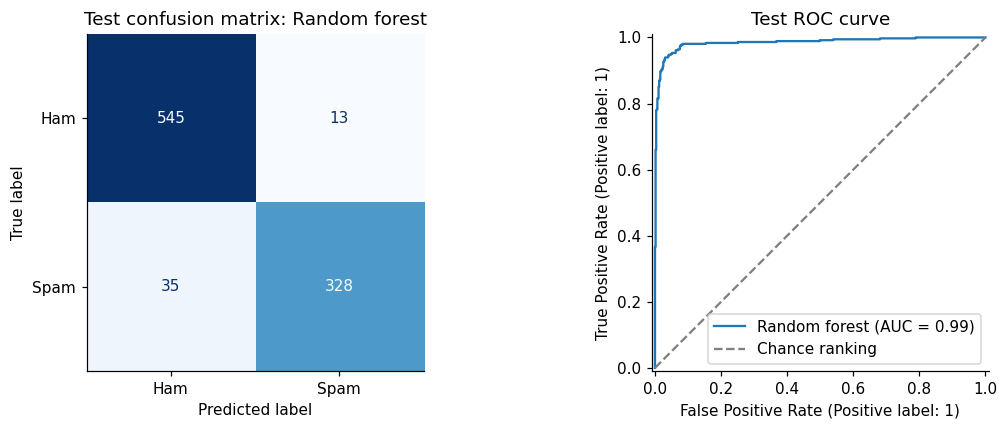

In [ ]:
pred = best_model.predict(X_test)
spam_probability = best_model.predict_proba(X_test)[:, list(best_model.classes_).index(1)]
baseline = clone(models['Majority baseline']).fit(X_train, y_train)
test_rows=[]
for name, fitted in [('Majority baseline', baseline), (best_name, best_model)]:
    p = fitted.predict(X_test)
    proba = fitted.predict_proba(X_test)[:, list(fitted.classes_).index(1)]
    test_rows.append({'Model':name, 'Accuracy':accuracy_score(y_test,p),
        'Spam precision':precision_score(y_test,p,zero_division=0),
        'Spam recall':recall_score(y_test,p), 'Spam F1':f1_score(y_test,p),
        'ROC AUC':roc_auc_score(y_test,proba)})
test_results=pd.DataFrame(test_rows)
display(test_results.round(4))
print(classification_report(y_test, pred, labels=[0,1], target_names=['Ham','Spam'],
                            digits=4, zero_division=0))
tn, fp, fn, tp = confusion_matrix(y_test,pred,labels=[0,1]).ravel()
print(f'Correct ham: {tn}; ham flagged as spam: {fp}; missed spam: {fn}; caught spam: {tp}')
print(f'False-positive rate among actual ham: {fp/(fp+tn):.2%}')
fig, axes=plt.subplots(1,2,figsize=(11,4))
ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=[0,1],
    display_labels=['Ham','Spam'], cmap='Blues', colorbar=False,ax=axes[0])
axes[0].set_title(f'Test confusion matrix: {best_name}')
RocCurveDisplay.from_predictions(y_test,spam_probability,name=best_name,ax=axes[1])
axes[1].plot([0,1],[0,1],linestyle='--',color='gray',label='Chance ranking')
axes[1].set_title('Test ROC curve')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
examples = X_test.head(10)[['word_freq_free','word_freq_money','char_freq_!',
                          'capital_run_length_longest']].copy()
examples.insert(0,'Original row index',examples.index)
examples['Actual class'] = y_test.iloc[:10].map({0:'Ham',1:'Spam'}).to_numpy()
examples['Predicted class'] = pd.Series(pred[:10]).map({0:'Ham',1:'Spam'}).to_numpy()
examples['Predicted spam probability'] = spam_probability[:10]
examples['Correct'] = pred[:10] == y_test.iloc[:10].to_numpy()
display(examples.reset_index(drop=True).round(4))

,Original row index,word_freq_free,word_freq_money,char_freq_!,capital_run_length_longest,Actual class,Predicted class,Predicted spam probability,Correct
0,5,0.00,0.00,0.000,15,Spam,Spam,0.5186,True
1,13,0.00,0.00,0.000,7,Spam,Spam,0.7095,True
2,14,5.35,0.00,0.357,24,Spam,Spam,0.9311,True
3,22,2.94,0.00,0.809,12,Spam,Spam,0.9408,True
4,24,0.00,0.00,0.392,22,Spam,Spam,0.9530,True
5,26,0.00,0.00,0.392,22,Spam,Spam,0.9530,True
6,27,0.00,3.33,0.368,12,Spam,Spam,0.7672,True
7,33,0.00,0.00,0.000,5,Spam,Ham,0.3817,False
8,49,0.26,0.26,0.278,40,Spam,Spam,0.9736,True
9,50,0.00,0.00,0.000,12,Spam,Ham,0.4746,False


# Results and conclusion

This project shows how labeled training emails can be used to classify unseen emails as spam or ham. Random forest achieved the highest mean cross validation F1 score of 0.9255, just outperforming logistic regression at 0.9205 and then Gaussian Naive Bayes at 0.8028. When evaluated on the 921 held out test emails random forest achieved 94.79% accuracy compared to 60.59% for the majority baseline. Its spam precision of 96.19% indicates that most emails flagged as spam were correctly classified while recall of 90.36% shows that it detected most actual spam emails. The model correctly identified 328 spam emails and 545 legitimate emails but did miss 35 spam emails and incorrectly flagged 13 legit emails. The errors show why accuracy alone is not enough when evaluating a spam filter because blocking legit messages also could be costly. The results are promising within this dataset and evaluation on newer and more varied emails would be necessary before I would feel comfortable applying the model to a current inbox.